# Source families and narrative annotations

The tables and figures below are calculated from official story metadata and
real training/validation annotation aggregates. Test QA is never opened. No
question, answer or story text is published. The saved aggregate identifies its
source revision and hashes; explicit recomputation uses the private source.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
from types import SimpleNamespace
from collections import Counter
from dataclasses import dataclass, asdict
from functools import lru_cache
import collections, csv, hashlib, html, io, json, math, random, re, statistics, string, subprocess, sys, time, zipfile
import numpy as np
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, HTML, SVG

ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "src").is_dir(), "Run in this repository"
FIGURES = ROOT / "assets/plots"
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update(
    {
        "svg.fonttype": "none",
        "font.size": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)


def sha(raw):
    return hashlib.sha256(raw).hexdigest()


def read_json(relative):
    return json.loads((ROOT / relative).read_text(encoding="utf-8"))


def table(rows, columns, caption):
    header = "".join("<th>" + html.escape(str(c)) + "</th>" for c in columns)
    body = "".join(
        "<tr>"
        + "".join("<td>" + html.escape(str(r.get(c, ""))) + "</td>" for c in columns)
        + "</tr>"
        for r in rows
    )
    display(
        HTML(
            "<table><caption>"
            + html.escape(caption)
            + "</caption><thead><tr>"
            + header
            + "</tr></thead><tbody>"
            + body
            + "</tbody></table>"
        )
    )


def show_figure(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / (name + ".png"), dpi=160)
    fig.savefig(FIGURES / (name + ".svg"))
    svg_path = FIGURES / (name + ".svg")
    svg_path.write_text(
        "\n".join(
            line.rstrip() for line in svg_path.read_text(encoding="utf-8").splitlines()
        )
        + "\n",
        encoding="utf-8",
        newline="\n",
    )
    display(SVG(svg_path.read_text(encoding="utf-8")))
    plt.close(fig)


print("Analysis kernel ready. No model weights loaded.")


Analysis kernel ready. No model weights loaded.


In [2]:
def histogram(values, edges):
    return {
        f"{low}-{high - 1}" if high is not None else f"{low}+": sum(
            value >= low and (high is None or value < high) for value in values
        )
        for low, high in zip(edges, edges[1:] + [None])
    }


def aggregate(metadata_path, staged):
    metadata_path, staged = Path(metadata_path), Path(staged)
    rows = list(csv.DictReader(metadata_path.open(encoding="utf-8")))
    manifest = json.loads((staged / "manifest.json").read_text(encoding="utf-8"))
    chosen = {r["id"]: r["split"] for r in manifest["stories"]}
    by_origin = {}
    for origin in sorted(set(r["origin"] for r in rows)):
        subset = [r for r in rows if r["origin"] == origin]
        by_origin[origin] = {
            "stories": len(subset),
            "metadata_qa": sum(int(r["questions"]) for r in subset),
            "official_split": dict(Counter(r["split"] for r in subset)),
            "study_split": dict(
                Counter(chosen.get(r["filename"], "excluded") for r in subset)
            ),
        }
    distributions = {}
    for split in ("train", "validation", "test", "excluded"):
        subset = [r for r in rows if chosen.get(r["filename"], "excluded") == split]
        lengths = [int(r["words"]) for r in subset]
        distributions[split] = {
            "stories": len(subset),
            "metadata_qa": sum(int(r["questions"]) for r in subset),
            "word_histogram": histogram(
                lengths, [0, 500, 1000, 2000, 4000, 8000, 16000]
            ),
            "median_words": statistics.median(lengths) if lengths else None,
        }
    annotation = {}
    for split in ("train", "validation"):
        stories, questions = load_split(staged, split)
        original = Counter((q["story"], q["source_question_id"]) for q in questions)
        annotation[split] = {
            "questions": len(questions),
            "stories": len(stories),
            "attribute": dict(Counter(q["attribute"] for q in questions)),
            "explicit": dict(Counter(q["explicit"] for q in questions)),
            "references": dict(Counter(len(q["references"]) for q in questions)),
            "evidence_sections": dict(
                Counter(len(q["gold_sections"]) for q in questions)
            ),
            "question_word_histogram": histogram(
                [len(q["question"].split()) for q in questions],
                [0, 5, 10, 15, 20, 40, 80],
            ),
            "answer_word_histogram": histogram(
                [len(q["references"][0].split()) for q in questions],
                [0, 2, 5, 10, 20, 40, 80, 160],
            ),
            "duplicate_original_ids": sum(n - 1 for n in original.values()),
            "canonical_ids_unique": len({q["id"] for q in questions}) == len(questions),
        }
    return {
        "dataset_revision": "a24ddc17364666b7c13a425b9970c87368b03417",
        "metadata_sha256": sha(metadata_path.read_bytes()),
        "staging_manifest_sha256": sha((staged / "manifest.json").read_bytes()),
        "by_origin": by_origin,
        "source_lengths": distributions,
        "annotations": annotation,
        "test_qa_parsed": False,
        "text_or_answers_published": False,
        "test_qa_count_source": "Official story metadata only, not test CSV parsing",
    }


In [3]:
RECOMPUTE = False
STAGED = ROOT / "data/interim/full-fairytale-v6"
metadata = (
    ROOT
    / "data/external/fairytaleqa/FairytaleQAData-a24ddc17364666b7c13a425b9970c87368b03417/story_meta.csv"
)
if RECOMPUTE:
    from src.narrative_training import load_split
    from src.data.prepare_fairytale import sha

    source_summary = aggregate(metadata, STAGED)
else:
    source_summary = read_json("docs/data-summary.json")
print("Recorded revision:", source_summary["dataset_revision"])
print("Test QA parsed:", source_summary["test_qa_parsed"])
table(
    [
        {
            "split": split,
            "stories": r["stories"],
            "metadata QA": r["metadata_qa"],
            "median words": r["median_words"],
        }
        for split, r in source_summary["source_lengths"].items()
    ],
    ["split", "stories", "metadata QA", "median words"],
    "Actual custom source-family partitions",
)


Recorded revision: a24ddc17364666b7c13a425b9970c87368b03417
Test QA parsed: False


split,stories,metadata QA,median words
train,200,7883,2037.0
validation,54,2372,1837.0
test,24,325,1040.0
excluded,0,0,None


## Official story splits and source-family separation

The official partition can place the same collection in training and evaluation.
The custom cohort keeps source families apart and uses every annotation. It is
not an official-split benchmark. This separation cannot rule out recurring plots
or pretrained exposure; test counts below come from metadata rather than labels.


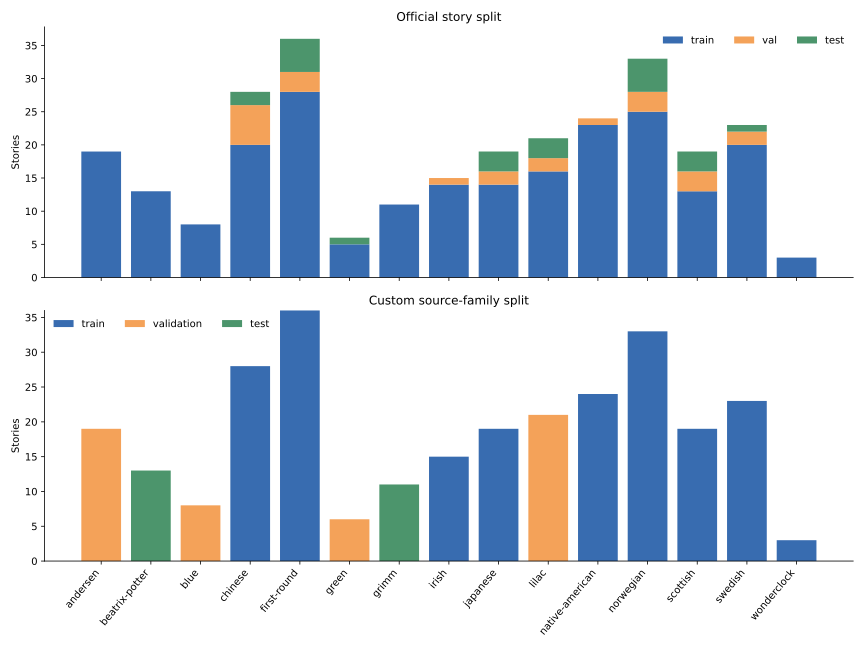

In [4]:
origins = list(source_summary["by_origin"])
fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True)
colors = {
    "train": "#386cb0",
    "validation": "#f4a259",
    "test": "#4c956c",
    "excluded": "#b9b9b9",
}
for ax, key, title, splits in [
    (axes[0], "official_split", "Official story split", ["train", "val", "test"]),
    (
        axes[1],
        "study_split",
        "Custom source-family split",
        ["train", "validation", "test"],
    ),
]:
    bottom = np.zeros(len(origins))
    for split in splits:
        values = np.array(
            [source_summary["by_origin"][o][key].get(split, 0) for o in origins]
        )
        ax.bar(
            range(len(origins)),
            values,
            bottom=bottom,
            label=split,
            color=colors.get(split, "#f4a259"),
        )
        bottom += values
    ax.set(title=title, ylabel="Stories")
    ax.legend(ncol=4, frameon=False)
axes[1].set_xticks(
    range(len(origins)),
    [o.replace("-fairybook", "") for o in origins],
    rotation=50,
    ha="right",
)
show_figure(fig, "source-family-splits")


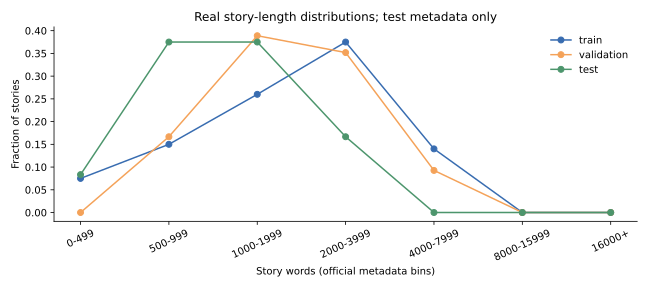

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
for split in ["train", "validation", "test"]:
    counts = source_summary["source_lengths"][split]["word_histogram"]
    values = np.array(list(counts.values()), dtype=float)
    ax.plot(
        list(counts),
        values / values.sum(),
        marker="o",
        label=split,
        color=colors[split],
    )
ax.set(
    xlabel="Story words (official metadata bins)",
    ylabel="Fraction of stories",
    title="Real story-length distributions; test metadata only",
)
ax.tick_params(axis="x", rotation=25)
ax.legend(frameon=False)
show_figure(fig, "story-word-distribution")


## Annotation mix and reference availability

These are train/validation aggregates. Test labels remain sealed. Multiple Lang
origins are not independent populations. Source-held-out stories that originally
belonged to the official training split may have only one reference answer.


split,QA,stories,duplicate original IDs,canonical IDs unique,references
train,7883,200,5,True,"{'1': 5953, '2': 1930}"
validation,2372,54,5,True,"{'1': 1937, '2': 435}"


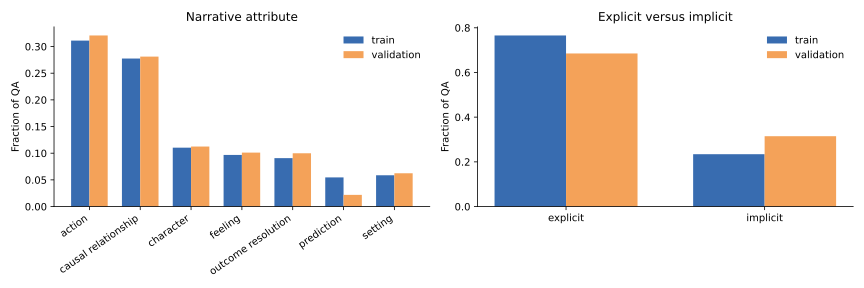

In [6]:
annotations = source_summary["annotations"]
table(
    [
        {
            "split": split,
            "QA": a["questions"],
            "stories": a["stories"],
            "duplicate original IDs": a["duplicate_original_ids"],
            "canonical IDs unique": a["canonical_ids_unique"],
            "references": str(a["references"]),
        }
        for split, a in annotations.items()
    ],
    [
        "split",
        "QA",
        "stories",
        "duplicate original IDs",
        "canonical IDs unique",
        "references",
    ],
    "Measured QA identity and reference audit",
)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
attributes = sorted(set().union(*(set(a["attribute"]) for a in annotations.values())))
mix_labels = sorted(set().union(*(set(a["explicit"]) for a in annotations.values())))
for index, (split, a) in enumerate(annotations.items()):
    values = np.array([a["attribute"].get(k, 0) for k in attributes]) / a["questions"]
    axes[0].bar(
        np.arange(len(attributes)) + (index - 0.5) * 0.36,
        values,
        width=0.36,
        label=split,
        color=colors[split],
    )
    values = np.array([a["explicit"].get(k, 0) for k in mix_labels]) / a["questions"]
    axes[1].bar(
        np.arange(len(mix_labels)) + (index - 0.5) * 0.36,
        values,
        width=0.36,
        label=split,
        color=colors[split],
    )
axes[0].set_xticks(range(len(attributes)), attributes, rotation=35, ha="right")
axes[0].set(title="Narrative attribute", ylabel="Fraction of QA")
axes[1].set_xticks(range(len(mix_labels)), mix_labels)
axes[1].set(title="Explicit versus implicit", ylabel="Fraction of QA")
axes[0].legend(frameon=False)
axes[1].legend(frameon=False)
show_figure(fig, "annotation-mix")


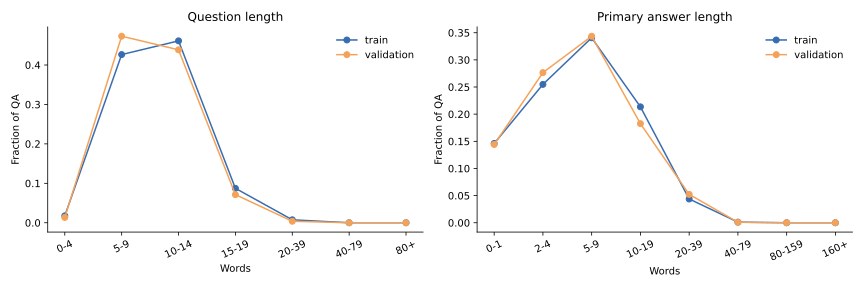

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for split, a in annotations.items():
    for ax, key, title in [
        (axes[0], "question_word_histogram", "Question length"),
        (axes[1], "answer_word_histogram", "Primary answer length"),
    ]:
        counts = a[key]
        values = np.array(list(counts.values()), dtype=float)
        ax.plot(
            list(counts),
            values / values.sum(),
            marker="o",
            label=split,
            color=colors[split],
        )
        ax.set(title=title, xlabel="Words", ylabel="Fraction of QA")
        ax.tick_params(axis="x", rotation=25)
        ax.legend(frameon=False)
show_figure(fig, "qa-length-distributions")


## Real ranking-supervision filters

Each annotated positive participates. Other gold evidence is excluded from the
negative pool. Questions without any nongold section yield no contrastive group;
no fake negative is added. Annotation omissions remain possible.


train_questions,train_stories,training_groups,training_pairs,questions_without_nongold_negative
7883,200,8848,43757,3


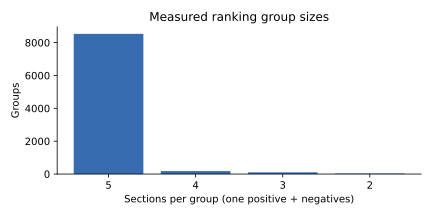

In [8]:
r = read_json("docs/ranking-supervision.json")
table(
    [
        {
            k: r[k]
            for k in [
                "train_questions",
                "train_stories",
                "training_groups",
                "training_pairs",
                "questions_without_nongold_negative",
            ]
        }
    ],
    [
        "train_questions",
        "train_stories",
        "training_groups",
        "training_pairs",
        "questions_without_nongold_negative",
    ],
    "Actually constructed all-training-QA groups",
)
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(
    list(r["group_size_distribution"]),
    list(r["group_size_distribution"].values()),
    color="#386cb0",
)
ax.set(
    xlabel="Sections per group (one positive + negatives)",
    ylabel="Groups",
    title="Measured ranking group sizes",
)
show_figure(fig, "ranking-group-distribution")
